# Chapter 5: What the importance chart can't tell you: is it rank or cause?
*Feature importance and its limits · also searched as: feature importance, permutation
importance, correlation is not causation*

Every model review ends on a bar chart of feature importance, and someone points at the top
bar and calls it the driver. This chapter computes importance by hand on twelve invented
members, so you can see exactly what it measures, and then the two things it cannot carry.

**Who needs the answer.** Kalpa's marketing lead, who will want to act on the top bar, and
the senior ML engineer, who says what the chart proves.

**The questions on the way.** What does permutation importance measure, by hand? What
happens when two columns are near twins? Does the top bar name a lever?

**You will be able to** compute permutation importance by shuffling a column and recounting,
explain why twins share credit, and say what a chart proves in one sentence.

## What does permutation importance measure, by hand?
Twelve invented members, their app visits and searches in the last week, and whether they
bought. The model is a rule: predict "buys" when visits plus searches is 8 or more.
Permutation importance shuffles one column (here, a fixed shuffle that moves every value six
rows down) and counts how many answers the same rule now gets right.

**Predict before you run.** The rule gets 11 of 12. With `searches` shuffled it gets
(A) about 11; (B) about 7; (C) 0.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

t = pd.DataFrame({                       # invented teaching table, twelve Kalpa members
    "visits":   [9, 7, 6, 5, 8, 2, 3, 1, 4, 2, 5, 4],
    "searches": [8, 7, 5, 6, 9, 1, 3, 2, 3, 2, 4, 5],
    "bought":   [1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0],
})
SHUFFLE = [6, 7, 8, 9, 10, 11, 0, 1, 2, 3, 4, 5]   # move every value six rows down
def right(v, s):
    return int((((v + s) >= 8).astype(int) == t["bought"].values).sum())
base = right(t["visits"].values, t["searches"].values)
rows = {"nothing shuffled": base,
        "visits shuffled": right(t["visits"].values[SHUFFLE], t["searches"].values),
        "searches shuffled": right(t["visits"].values, t["searches"].values[SHUFFLE]),
        "both shuffled": right(t["visits"].values[SHUFFLE], t["searches"].values[SHUFFLE])}
imp = pd.DataFrame({"right of 12": rows, "importance (answers lost)": {k: base - v for k, v in rows.items()}})
imp

,right of 12,importance (answers lost)
nothing shuffled,11,0
visits shuffled,9,2
searches shuffled,7,4
both shuffled,3,8


**What happened.** B. Shuffling `searches` costs 4 answers and shuffling `visits` costs 2,
so the rule leans more on searches. Shuffling both costs 8. That is all permutation
importance measures: how much this fitted model's score falls when one column stops
lining up with its rows. In code it is `sklearn.inspection.permutation_importance`, scored
on validation rows, which case 3 runs on the bank.

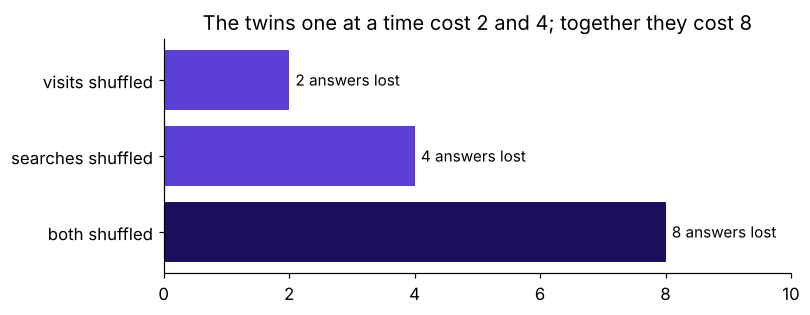

correlation of visits and searches: 0.94


In [2]:
fig, ax = plt.subplots(figsize=(7.5, 3))
lost = imp["importance (answers lost)"].drop("nothing shuffled")
ax.barh(lost.index, lost.values, color=[VIOLET, VIOLET, INK])
for i, x in enumerate(lost.values):
    ax.text(x + 0.1, i, f"{x} answers lost", va="center", fontsize=10)
ax.set_xlim(0, 10); ax.invert_yaxis()
ax.set_title("The twins one at a time cost 2 and 4; together they cost 8")
plt.tight_layout(); plt.show()
print("correlation of visits and searches:", round(float(t["visits"].corr(t["searches"])), 2))

## What happens when two columns are near twins?
`visits` and `searches` correlate at 0.94: they are near twins. Each one alone costs little
when shuffled, because its twin still carries most of the signal, and together they cost
more than the two single costs added up. A chart that lists them one at a time understates
both, and the split of credit between them depends on accidents of the sample. When columns
have close partners, shuffle them as a group and read the group.

## Does the top bar name a lever?
**Predict before you run.** Marketing sees `searches` at the top and proposes push
notifications that drive members to search more. The chart says that pushing searches up
will (A) raise purchases; (B) nothing about what happens if searches are pushed up.

**What happened.** B. A member searches because they already mean to buy; the search is a
symptom of intent. The chart ranks what this model leans on; it does not say that changing
the column changes the outcome. The way to test the lever is the fair comparison from
Week 1: push a random half of members, leave the other half, and compare purchases.

In [3]:
check("the rule gets 11 of 12 before any shuffle", base == 11)
check("shuffling both twins costs more than the two single costs added", rows["both shuffled"] < rows["visits shuffled"] + rows["searches shuffled"] - base)
check("the twins correlate above 0.9", t["visits"].corr(t["searches"]) > 0.9)

PASS  the rule gets 11 of 12 before any shuffle
PASS  shuffling both twins costs more than the two single costs added
PASS  the twins correlate above 0.9


## What are the rules, and what flips each one?
1. Importance ranks how much a fitted model leans on a column; it names a lever only when
   the column was changed in a fair test.
2. Shuffle close partners as a group; a single-column importance is readable only when the
   column has no twin.
3. Compute importance on validation rows; on training rows it rewards what the model
   memorised.
4. Run the column audit before the chart: a leaked column tops every importance chart, so
   the chart can never be the audit.

The case chapters now take all five ideas to the bank's 41,188 calls.